<a href="https://colab.research.google.com/github/varsityboi/speech-emotion-recognition/blob/main/04_transformer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, tensorflow as tf, matplotlib.pyplot as plt
print("GPU:", tf.config.list_physical_devices("GPU"))

PROJECT_DIR = "/content/drive/MyDrive/SER_Project"
MODEL_DIR = f"{PROJECT_DIR}/models"
EMOTIONS = ["angry", "disgust", "fear", "happy", "neutral", "sad"]

# Pick which spectrograms to use: "scaled" (original) or "noscale" (kept loudness)
DATA_VERSION = "noscale"

if DATA_VERSION == "scaled":
    X = np.load(f"{PROJECT_DIR}/logmel_X.npy")
    stats = np.load(f"{PROJECT_DIR}/norm_stats.npz")
else:
    X = np.load(f"{PROJECT_DIR}/logmel_X_noscale.npy")
    stats = np.load(f"{PROJECT_DIR}/norm_stats_noscale.npz")
mean, std = stats["mean"], stats["std"]
data = pd.read_csv(f"{PROJECT_DIR}/logmel_index.csv")

def get_split(name):
    idx = np.where(data["split"] == name)[0]
    x = (X[idx].astype(np.float32) - mean[None, :, None]) / std[None, :, None]
    return x[..., None], data["label"].values[idx]

X_train, y_train = get_split("train")
X_val,   y_val   = get_split("val")
X_test,  y_test  = get_split("test")
X_rav,   y_rav   = get_split("ravdess_test")
print("Using:", DATA_VERSION, "|", X_train.shape, X_val.shape, X_test.shape, X_rav.shape)

Mounted at /content/drive
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Using: noscale | (5329, 128, 351, 1) (1065, 128, 351, 1) (1048, 128, 351, 1) (1056, 128, 351, 1)


In [ ]:
import keras
from tensorflow.keras import layers, models

@keras.saving.register_keras_serializable()
class SpecAugment(layers.Layer):
    def __init__(self, freq_mask=15, time_mask=35, n_freq=2, n_time=2, **kw):
        super().__init__(**kw)
        self.freq_mask, self.time_mask = freq_mask, time_mask
        self.n_freq, self.n_time = n_freq, n_time

    def _mask(self, x, axis, max_w, n):
        size, batch = tf.shape(x)[axis], tf.shape(x)[0]
        idx = tf.range(size)[None, :]
        keep = tf.ones([batch, size], dtype=tf.bool)
        for _ in range(n):
            w = tf.random.uniform([batch, 1], 0, max_w + 1, dtype=tf.int32)
            s = tf.random.uniform([batch, 1], 0, size, dtype=tf.int32)
            keep &= ~((idx >= s) & (idx < s + w))
        keep = tf.cast(keep, x.dtype)
        return x * (keep[:, :, None, None] if axis == 1 else keep[:, None, :, None])

    def call(self, x, training=None):
        if not training:
            return x
        x = self._mask(x, 1, self.freq_mask, self.n_freq)
        return self._mask(x, 2, self.time_mask, self.n_time)

    def get_config(self):
        return {**super().get_config(), "freq_mask": self.freq_mask, "time_mask": self.time_mask,
                "n_freq": self.n_freq, "n_time": self.n_time}

@keras.saving.register_keras_serializable()
class PositionalEmbedding(layers.Layer):
    def __init__(self, length, dim, **kw):
        super().__init__(**kw)
        self.length, self.dim = length, dim
        self.pos = layers.Embedding(length, dim)

    def call(self, x):
        return x + self.pos(tf.range(self.length))[None, :, :]

    def get_config(self):
        return {**super().get_config(), "length": self.length, "dim": self.dim}

D_MODEL, HEADS, FF, BLOCKS = 128, 4, 256, 4

def transformer_block(x):
    # attention: each moment looks at all moments
    a = layers.LayerNormalization()(x)
    a = layers.MultiHeadAttention(num_heads=HEADS, key_dim=D_MODEL // HEADS, dropout=0.1)(a, a)
    x = x + layers.Dropout(0.1)(a)
    # feed-forward: each moment processes what it gathered
    f = layers.LayerNormalization()(x)
    f = layers.Dense(FF, activation="gelu")(f)
    f = layers.Dense(D_MODEL)(f)
    x = x + layers.Dropout(0.1)(f)
    return x

inputs = layers.Input(shape=(128, 351, 1))
x = SpecAugment()(inputs)
x = layers.Permute((2, 1, 3))(x)
x = layers.Reshape((351, 128))(x)
x = layers.Dense(D_MODEL)(x)
x = PositionalEmbedding(351, D_MODEL)(x)
for _ in range(BLOCKS):
    x = transformer_block(x)
x = layers.LayerNormalization()(x)
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(6, activation="softmax")(x)

transformer = models.Model(inputs, outputs, name="transformer_specaug")
transformer.compile(optimizer=tf.keras.optimizers.Adam(3e-4, clipnorm=1.0),
                    loss="sparse_categorical_crossentropy", metrics=["accuracy"])
transformer.summary()

Model: "transformer_specaug"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 351,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spec_augment        │ (None, 128, 351,  │          0 │ input_layer[0][0] │
│ (SpecAugment)       │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute (Permute)   │ (None, 351, 128,  │          0 │ spec_augment[0][… │
│                     │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 351, 128)  │          0 │ permute[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 351, 128)  │     16,512 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, 351, 128)  │     44,928 │ dense[0][0]       │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 351, 128)  │        256 │ positional_embed… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 351, 128)  │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 351, 128)  │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 351, 128)  │          0 │ positional_embed… │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 351, 128)  │        256 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 351, 256)  │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 351, 128)  │     32,896 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 351, 128)  │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 351, 128)  │          0 │ add[0][0],        │
│                     │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 351, 128)  │        256 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 351, 128)  │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 351, 128)  │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 351, 128)  │          0 │ add_1[0][0],      │
│                     │                   │            │ dropout_4[0][0] 

 Total params: 592,390 (2.26 MB)

 Trainable params: 592,390 (2.26 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 70s 222ms/step - accuracy: 0.3243 - loss: 1.6299 - val_accuracy: 0.3455 - val_loss: 1.6176 - learning_rate: 3.0000e-04
Epoch 2/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 9s 56ms/step - accuracy: 0.3871 - loss: 1.4889 - val_accuracy: 0.3427 - val_loss: 1.5417 - learning_rate: 3.0000e-04
Epoch 3/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 10s 57ms/step - accuracy: 0.3986 - loss: 1.4504 - val_accuracy: 0.3737 - val_loss: 1.5562 - learning_rate: 3.0000e-04
Epoch 4/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 9s 56ms/step - accuracy: 0.4241 - loss: 1.4180 - val_accuracy: 0.3305 - val_loss: 1.6419 - learning_rate: 3.0000e-04
Epoch 5/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 10s 57ms/step - accuracy: 0.4245 - loss: 1.4155 - val_accuracy: 0.3709 - val_loss: 1.4969 - learning_rate: 3.0000e-04
Epoch 6/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 10s 57ms/step - accuracy: 0.4361 - loss: 1.3960 - val_accuracy: 0.3484 - val_loss: 1.5077 - learning_rate: 3.0000e-04
Epoch 7/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 10s 59ms/step

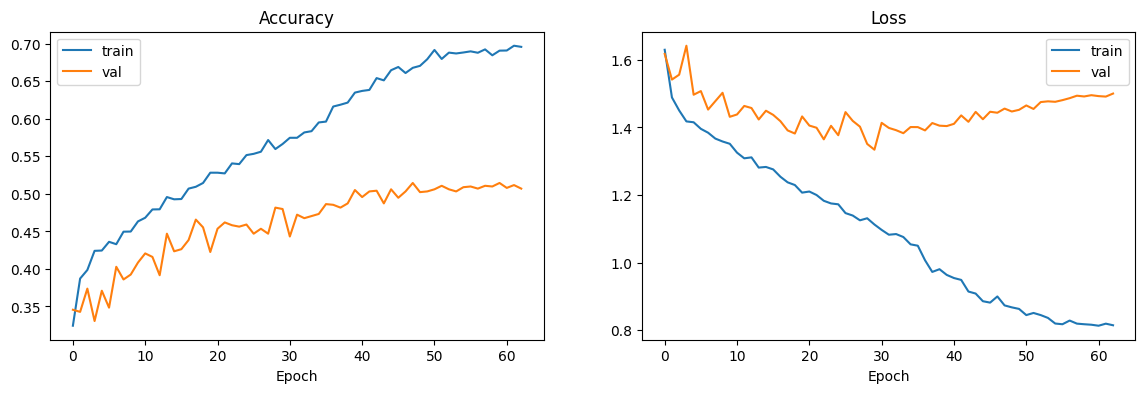

All saved to /content/drive/MyDrive/SER_Project


In [ ]:
import os, json
import pandas as pd
name = f"transformer_specaug_{DATA_VERSION}"
LOG_DIR, FIG_DIR = f"{PROJECT_DIR}/logs", f"{PROJECT_DIR}/figures"
os.makedirs(LOG_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=15,
                                     restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                         patience=6, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(f"{MODEL_DIR}/{name}_best.keras",
                                       monitor="val_accuracy", save_best_only=True),
    tf.keras.callbacks.CSVLogger(f"{LOG_DIR}/{name}_history.csv"),
]

history = transformer.fit(X_train, y_train,
                          validation_data=(X_val, y_val),
                          epochs=80, batch_size=32,
                          callbacks=callbacks)

# ---- results ----
best_epoch = int(np.argmax(history.history["val_accuracy"])) + 1
val_acc = transformer.evaluate(X_val, y_val, verbose=0)[1]
rav_acc = transformer.evaluate(X_rav, y_rav, verbose=0)[1]
result = {"model": name, "best_epoch": best_epoch,
          "val_acc": round(val_acc * 100, 2), "ravdess_acc": round(rav_acc * 100, 2)}
json.dump(result, open(f"{LOG_DIR}/{name}_result.json", "w"), indent=2)
print(result)

h = history.history
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(h["accuracy"], label="train"); axes[0].plot(h["val_accuracy"], label="val")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(h["loss"], label="train"); axes[1].plot(h["val_loss"], label="val")
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.savefig(f"{FIG_DIR}/{name}_curves.png", dpi=150)
plt.show()
print("All saved to", PROJECT_DIR)